# PM25 Bandung

In [2]:
# Di Colab: clone repo. Di laptop: langsung pakai folder repo yang sudah ada.
import os, subprocess
from pathlib import Path

REPO = "https://github.com/alfdmsr/pm25-forecast-bandung.git"

if not Path("data/raw.csv").exists():
    if not Path("pm25-forecast-bandung").exists():
        subprocess.run(["git", "clone", "--depth", "1", REPO], check=True)
    os.chdir("pm25-forecast-bandung")

print("folder kerja:", Path.cwd())
print("ada raw.csv:", Path("data/raw.csv").exists())


folder kerja: /content/pm25-forecast-bandung
ada raw.csv: True


In [9]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

RANDOM_STATE = 42
df = pd.read_csv("data/raw.csv")
print(f"{len(df):} baris, {df.shape[1]} kolom")
df.head()

87650 baris, 8 kolom


,waktu,stasiun,pm25_ugm3,suhu_C,kelembaban_pct,kecepatan_angin_ms,arah_angin_deg,curah_hujan_mm
0,2024-07-01 00:00,Dago,26.9,19.1,89.0,0.9,112.0,0.0
1,2024-07-01 01:00,Dago,25.3,18.4,86.0,1.2,158.0,0.0
2,2024-07-01 02:00,Dago,27.8,17.3,95.0,0.8,97.0,0.0
3,2024-07-01 03:00,Dago,26.0,16.6,89.0,0.8,66.0,0.0
4,2024-07-01 04:00,Dago,26.6,16.0,91.0,0.1,104.0,0.0


## 1. Data Understanding

In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 87650 entries, 0 to 87649
Data columns (total 8 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   waktu               87650 non-null  object 
 1   stasiun             87650 non-null  object 
 2   pm25_ugm3           87506 non-null  float64
 3   suhu_C              87506 non-null  float64
 4   kelembaban_pct      87506 non-null  float64
 5   kecepatan_angin_ms  86773 non-null  float64
 6   arah_angin_deg      87650 non-null  float64
 7   curah_hujan_mm      87650 non-null  float64
dtypes: float64(6), object(2)
memory usage: 5.3+ MB


In [8]:
df.describe().round(2)

,pm25_ugm3,suhu_C,kelembaban_pct,kecepatan_angin_ms,arah_angin_deg,curah_hujan_mm
count,87506.00,87506.00,87506.00,86773.00,87650.00,87650.00
mean,23.99,23.06,80.84,1.95,179.37,0.38
std,47.18,3.67,9.85,1.10,84.51,1.52
min,-999.00,12.00,51.00,0.10,0.00,0.00
25%,17.20,19.80,73.00,1.00,110.00,0.00
50%,24.00,23.10,81.00,2.00,178.00,0.00
75%,32.60,26.30,89.00,2.70,248.00,0.00
max,128.40,31.90,100.00,7.90,360.00,24.90


In [10]:
display(df.describe().T)

,count,mean,std,min,25%,50%,75%,max
pm25_ugm3,87506.0,23.992318,47.184571,-999.0,17.2,24.0,32.6,128.4
suhu_C,87506.0,23.056426,3.669410,12.0,19.8,23.1,26.3,31.9
kelembaban_pct,87506.0,80.837405,9.854038,51.0,73.0,81.0,89.0,100.0
kecepatan_angin_ms,86773.0,1.949231,1.101400,0.1,1.0,2.0,2.7,7.9
arah_angin_deg,87650.0,179.366207,84.512295,0.0,110.0,178.0,248.0,360.0
curah_hujan_mm,87650.0,0.377724,1.522590,0.0,0.0,0.0,0.0,24.9


In [11]:
# Categorical statistics
display(df.describe(include="object").T)

,count,unique,top,freq
waktu,87650,17520,2024-09-14 04:00,7
stasiun,87650,16,Dago,17025


In [12]:
print("jumlah variasi nama stasiun:", df["stasiun"].nunique())

print("\nDistribusi nama stasiun:")
display(df["stasiun"].value_counts(dropna=False))


jumlah variasi nama stasiun: 16

Distribusi nama stasiun:


,count
stasiun,
Dago,17025
Cibeureum,17011
Soekarno-Hatta,16997
Ujungberung,16995
Antapani,16987
Ujung Berung,286
antapani,285
ujungberung,264
Cibeureum,260


## 2. Data Quality

In [14]:
# missing value
hilang = pd.DataFrame({
    "Missing Count": df.isnull().sum(),
    "Missing Percentage": (
        df.isnull().mean() * 100
    )
})

display(hilang.sort_values(
    by="Missing Percentage",
    ascending=False
))

,Missing Count,Missing Percentage
kecepatan_angin_ms,877,1.00057
suhu_C,144,0.16429
kelembaban_pct,144,0.16429
pm25_ugm3,144,0.16429
waktu,0,0.00000
stasiun,0,0.00000
arah_angin_deg,0,0.00000
curah_hujan_mm,0,0.00000


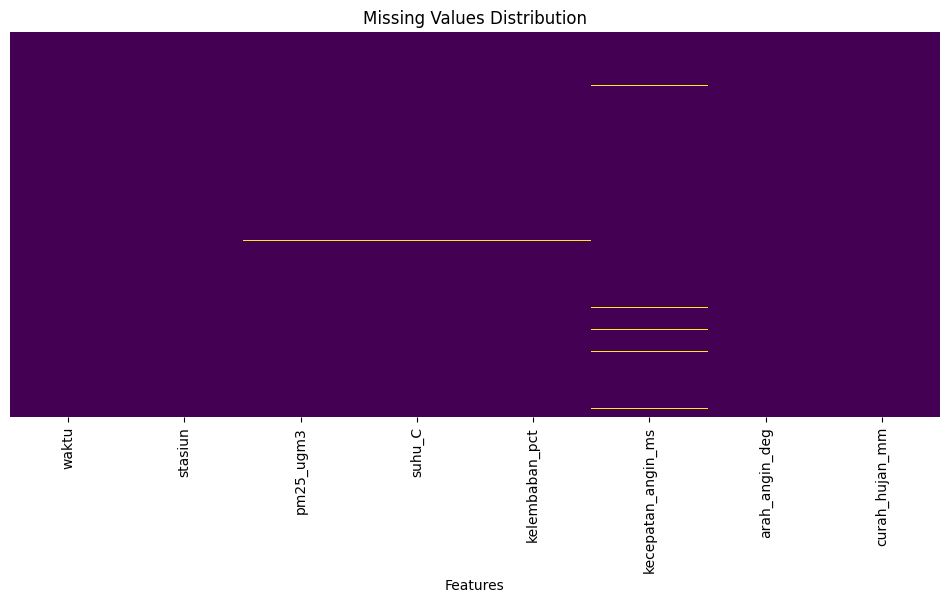

In [15]:
plt.figure(figsize=(12, 5))

sns.heatmap(
    df.isnull(),
    cbar=False,
    yticklabels=False,
    cmap="viridis"
)

plt.title("Missing Values Distribution")
plt.xlabel("Features")
plt.show()

In [16]:
# duplikasi
jumlah_duplikasi = df.duplicated().sum()
print("kolom yang sama:", jumlah_duplikasi)

duplikasi_waktu_di_stasiun = df.duplicated(
    subset=["waktu", "stasiun"]
).sum()

print(
    "Duplikat timestamp stasiun:", duplikasi_waktu_di_stasiun
)

kolom yang sama: 398
Duplikat timestamp stasiun: 404


In [17]:
# nilai tidak valid
numeric_cols = df.select_dtypes(
    include=np.number
).columns

for col in numeric_cols:
    print(f"\n===== {col} =====")
    print("Minimum:", df[col].min())
    print("Maximum:", df[col].max())
    print("Negative values:", (df[col] < 0).sum())
    print("-999 values:", (df[col] == -999).sum())


===== pm25_ugm3 =====
Minimum: -999.0
Maximum: 128.4
Negative values: 173
-999 values: 173

===== suhu_C =====
Minimum: 12.0
Maximum: 31.9
Negative values: 0
-999 values: 0

===== kelembaban_pct =====
Minimum: 51.0
Maximum: 100.0
Negative values: 0
-999 values: 0

===== kecepatan_angin_ms =====
Minimum: 0.1
Maximum: 7.9
Negative values: 0
-999 values: 0

===== arah_angin_deg =====
Minimum: 0.0
Maximum: 360.0
Negative values: 0
-999 values: 0

===== curah_hujan_mm =====
Minimum: 0.0
Maximum: 24.9
Negative values: 0
-999 values: 0


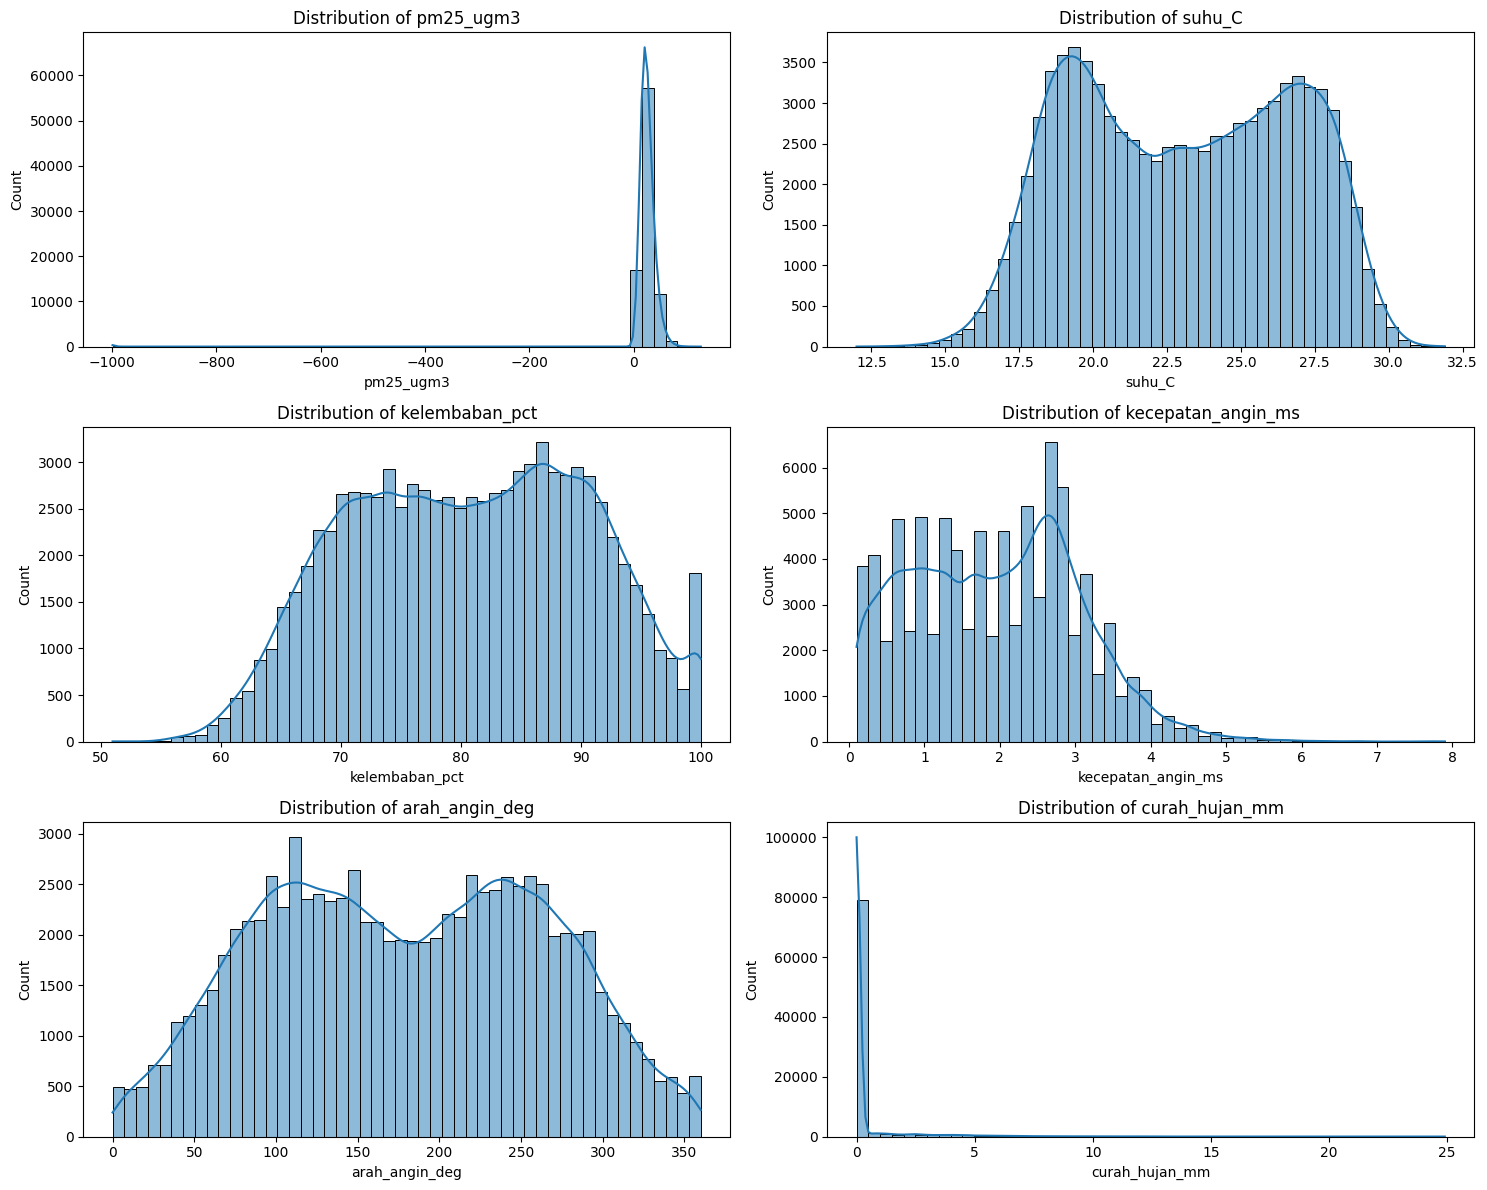

In [18]:
numerical_features = [
    "pm25_ugm3",
    "suhu_C",
    "kelembaban_pct",
    "kecepatan_angin_ms",
    "arah_angin_deg",
    "curah_hujan_mm"
]

fig, axes = plt.subplots(
    3, 2,
    figsize=(15, 12)
)

axes = axes.flatten()

for i, col in enumerate(numerical_features):
    sns.histplot(
        data=df,
        x=col,
        bins=50,
        kde=True,
        ax=axes[i]
    )

    axes[i].set_title(f"Distribution of {col}")

plt.tight_layout()
plt.show()

## 3. Data Cleaning

In [19]:
df_clean = df.copy()

df_clean["stasiun"] = (
    df_clean["stasiun"]
    .astype("string")
    .str.strip()
    .str.lower()
    .str.replace(r"[\s-]+", "", regex=True)
)

# standarisasi nama stasiun
station_mapping = {
    "dago": "Dago",
    "soekarnohatta": "Soekarno-Hatta",
    "soetta": "Soekarno-Hatta",
    "cibeureum": "Cibeureum",
    "antapani": "Antapani",
    "ujungberung": "Ujungberung"
}

df_clean["stasiun"] = df_clean["stasiun"].map(
    station_mapping
)

print("Station distribution after normalization:")
display(df_clean["stasiun"].value_counts(dropna=False))

Station distribution after normalization:


,count
stasiun,
Ujungberung,17545
Antapani,17530
Dago,17527
Cibeureum,17526
Soekarno-Hatta,17522


In [22]:
print("Unknown station values:")
display(
    df_clean[df_clean["stasiun"].isna()].T
)

Unknown station values:


""
waktu
stasiun
pm25_ugm3
suhu_C
kelembaban_pct
kecepatan_angin_ms
arah_angin_deg
curah_hujan_mm


In [23]:
df_clean["waktu"] = pd.to_datetime(
    df_clean["waktu"],
    errors="coerce"
)

print("Invalid timestamps:", df_clean["waktu"].isna().sum())

print("Start:", df_clean["waktu"].min())
print("End:", df_clean["waktu"].max())

print("Timezone information:", df_clean["waktu"].dt.tz)

Invalid timestamps: 0
Start: 2024-07-01 00:00:00
End: 2026-06-30 23:00:00
Timezone information: None


In [24]:
# cek nilai sentinel
sentinel_counts = (df_clean == -999).sum()

display(sentinel_counts)

,0
waktu,0
stasiun,0
pm25_ugm3,173
suhu_C,0
kelembaban_pct,0
kecepatan_angin_ms,0
arah_angin_deg,0
curah_hujan_mm,0


In [31]:
df_clean["pm25_ugm3"] = (
    df_clean["pm25_ugm3"]
    .replace(-999, np.nan)
)

print(
    "Missing PM2.5 after sentinel handling:",
    df_clean["pm25_ugm3"].isna().sum()
)

Missing PM2.5 after sentinel handling: 315


In [33]:
before = len(df_clean)

df_clean = df_clean.drop_duplicates()

after = len(df_clean)

print("Rows before:", before)
print("Rows after:", after)
print("Removed exact duplicates:", before - after)

Rows before: 87252
Rows after: 87252
Removed exact duplicates: 0


In [34]:
# Find conflicting station-timestamp records
key_cols = ["waktu", "stasiun"]

conflict_summary = (
    df_clean
    .groupby(key_cols, dropna=False)
    .size()
    .reset_index(name="record_count")
)

conflicts = conflict_summary[
    conflict_summary["record_count"] > 1
]

print("Conflicting timestamp-station groups:", len(conflicts))

display(conflicts.head(20))

Conflicting timestamp-station groups: 7


,waktu,stasiun,record_count
43585,2025-06-30 17:00:00,Soekarno-Hatta,2
43590,2025-06-30 18:00:00,Soekarno-Hatta,2
43595,2025-06-30 19:00:00,Soekarno-Hatta,2
43600,2025-06-30 20:00:00,Soekarno-Hatta,2
43605,2025-06-30 21:00:00,Soekarno-Hatta,2
43610,2025-06-30 22:00:00,Soekarno-Hatta,2
43615,2025-06-30 23:00:00,Soekarno-Hatta,2


In [35]:
conflict_details = df_clean.merge(
    conflicts[key_cols],
    on=key_cols,
    how="inner"
).sort_values(key_cols)

display(conflict_details.head(50))

,waktu,stasiun,pm25_ugm3,suhu_C,kelembaban_pct,kecepatan_angin_ms,arah_angin_deg,curah_hujan_mm
0,2025-06-30 17:00:00,Soekarno-Hatta,42.5,26.5,70.0,3.1,121.0,0.0
7,2025-06-30 17:00:00,Soekarno-Hatta,44.5,19.6,92.0,0.7,65.0,0.0
1,2025-06-30 18:00:00,Soekarno-Hatta,44.6,26.7,65.0,2.9,17.0,0.0
8,2025-06-30 18:00:00,Soekarno-Hatta,40.2,18.4,88.0,1.6,92.0,0.0
2,2025-06-30 19:00:00,Soekarno-Hatta,39.6,26.2,73.0,2.7,118.0,0.0
9,2025-06-30 19:00:00,Soekarno-Hatta,54.1,19.0,91.0,0.4,15.0,0.0
3,2025-06-30 20:00:00,Soekarno-Hatta,44.1,25.2,74.0,1.9,145.0,0.0
10,2025-06-30 20:00:00,Soekarno-Hatta,49.5,18.4,100.0,0.1,145.0,0.0
4,2025-06-30 21:00:00,Soekarno-Hatta,39.8,24.3,76.0,1.7,46.0,0.0
11,2025-06-30 21:00:00,Soekarno-Hatta,38.6,18.2,93.0,2.4,43.0,0.0


In [36]:
# Keep conflict records separately for investigation
df_conflicts = conflict_details.copy()

# Remove all conflicting timestamp-station groups
df_clean = df_clean.merge(
    conflicts[key_cols],
    on=key_cols,
    how="left",
    indicator=True
)

df_clean = (
    df_clean[df_clean["_merge"] == "left_only"]
    .drop(columns="_merge")
)

print("Rows after conflict quarantine:", len(df_clean))

Rows after conflict quarantine: 87238


In [37]:
validity_checks = {
    "pm25_ugm3": lambda x: x >= 0,
    "kelembaban_pct": lambda x: x.between(0, 100),
    "kecepatan_angin_ms": lambda x: x >= 0,
    "arah_angin_deg": lambda x: x.between(0, 360),
    "curah_hujan_mm": lambda x: x >= 0
}

for col, condition in validity_checks.items():
    invalid = df_clean[col].notna() & ~condition(df_clean[col])

    print(f"{col}: {invalid.sum()} potentially invalid values")

pm25_ugm3: 0 potentially invalid values
kelembaban_pct: 0 potentially invalid values
kecepatan_angin_ms: 0 potentially invalid values
arah_angin_deg: 0 potentially invalid values
curah_hujan_mm: 0 potentially invalid values


In [38]:
df_clean = df_clean.sort_values(
    ["stasiun", "waktu"]
).reset_index(drop=True)

print("Final cleaned shape:", df_clean.shape)

display(df_clean.head())

Final cleaned shape: (87238, 8)


,waktu,stasiun,pm25_ugm3,suhu_C,kelembaban_pct,kecepatan_angin_ms,arah_angin_deg,curah_hujan_mm
0,2024-07-01 00:00:00,Antapani,34.9,21.5,89.0,0.9,112.0,0.0
1,2024-07-01 01:00:00,Antapani,33.1,19.0,86.0,1.2,158.0,0.0
2,2024-07-01 02:00:00,Antapani,38.2,19.2,95.0,0.8,97.0,0.0
3,2024-07-01 03:00:00,Antapani,34.2,18.0,89.0,0.8,66.0,0.0
4,2024-07-01 04:00:00,Antapani,37.6,17.6,91.0,0.1,104.0,0.0


## 4. Univariate Analysis

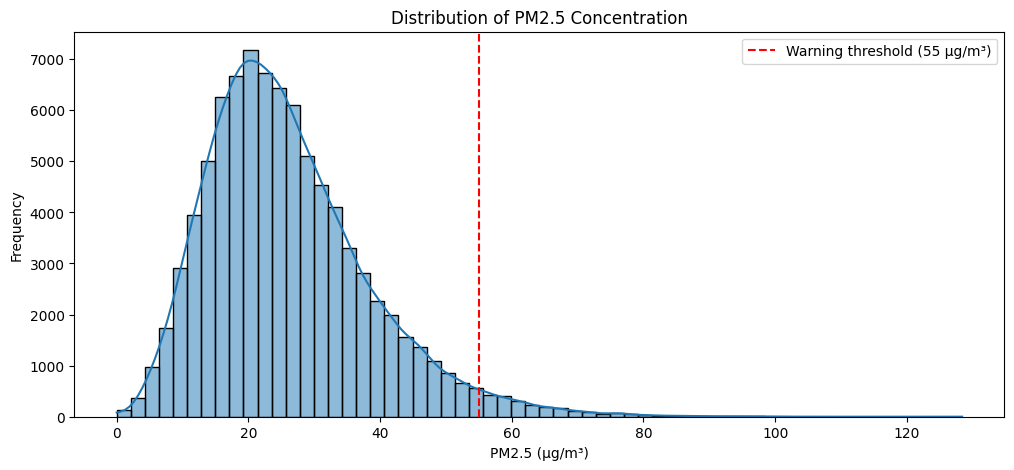

In [39]:
plt.figure(figsize=(12, 5))

sns.histplot(
    data=df_clean,
    x="pm25_ugm3",
    bins=60,
    kde=True
)

plt.axvline(
    55,
    color="red",
    linestyle="--",
    label="Warning threshold (55 µg/m³)"
)

plt.title("Distribution of PM2.5 Concentration")
plt.xlabel("PM2.5 (µg/m³)")
plt.ylabel("Frequency")
plt.legend()

plt.show()

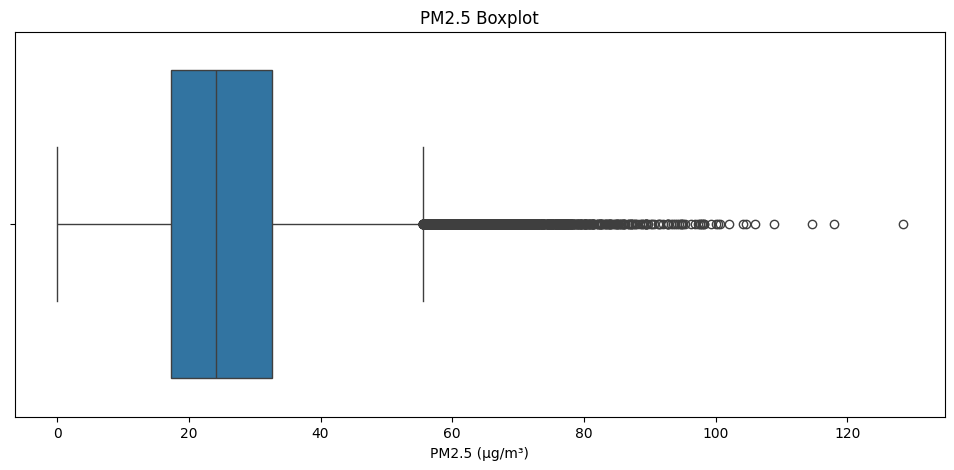

In [40]:
plt.figure(figsize=(12, 5))

sns.boxplot(
    data=df_clean,
    x="pm25_ugm3"
)

plt.title("PM2.5 Boxplot")
plt.xlabel("PM2.5 (µg/m³)")

plt.show()

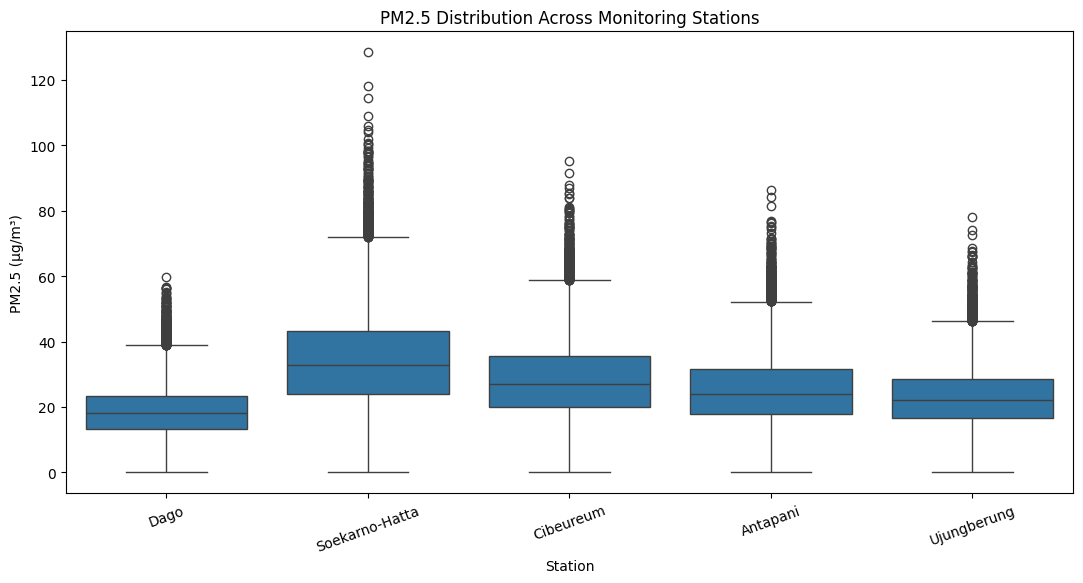

In [41]:
plt.figure(figsize=(13, 6))

sns.boxplot(
    data=df_clean,
    x="stasiun",
    y="pm25_ugm3",
    order=[
        "Dago",
        "Soekarno-Hatta",
        "Cibeureum",
        "Antapani",
        "Ujungberung"
    ]
)

plt.title("PM2.5 Distribution Across Monitoring Stations")
plt.xlabel("Station")
plt.ylabel("PM2.5 (µg/m³)")
plt.xticks(rotation=20)

plt.show()

In [42]:
station_stats = (
    df_clean
    .groupby("stasiun")["pm25_ugm3"]
    .agg([
        "count",
        "mean",
        "median",
        "std",
        "min",
        "max"
    ])
    .round(2)
)

display(station_stats)

,count,mean,median,std,min,max
stasiun,,,,,,
Antapani,17426,25.26,24.0,10.71,0.0,86.2
Cibeureum,17265,28.56,27.1,12.05,0.0,95.1
Dago,17424,18.85,18.0,7.92,0.0,59.8
Soekarno-Hatta,17390,34.54,32.8,14.79,0.0,128.4
Ujungberung,17418,22.92,22.0,9.29,0.0,78.0


## 5. Temporal Analysis

In [43]:
df_clean["hour"] = df_clean["waktu"].dt.hour
df_clean["day"] = df_clean["waktu"].dt.day
df_clean["day_of_week"] = df_clean["waktu"].dt.dayofweek
df_clean["month"] = df_clean["waktu"].dt.month
df_clean["year"] = df_clean["waktu"].dt.year
df_clean["date"] = df_clean["waktu"].dt.date

df_clean.head()

,waktu,stasiun,pm25_ugm3,suhu_C,kelembaban_pct,kecepatan_angin_ms,arah_angin_deg,curah_hujan_mm,hour,day,day_of_week,month,year,date
0,2024-07-01 00:00:00,Antapani,34.9,21.5,89.0,0.9,112.0,0.0,0,1,0,7,2024,2024-07-01
1,2024-07-01 01:00:00,Antapani,33.1,19.0,86.0,1.2,158.0,0.0,1,1,0,7,2024,2024-07-01
2,2024-07-01 02:00:00,Antapani,38.2,19.2,95.0,0.8,97.0,0.0,2,1,0,7,2024,2024-07-01
3,2024-07-01 03:00:00,Antapani,34.2,18.0,89.0,0.8,66.0,0.0,3,1,0,7,2024,2024-07-01
4,2024-07-01 04:00:00,Antapani,37.6,17.6,91.0,0.1,104.0,0.0,4,1,0,7,2024,2024-07-01


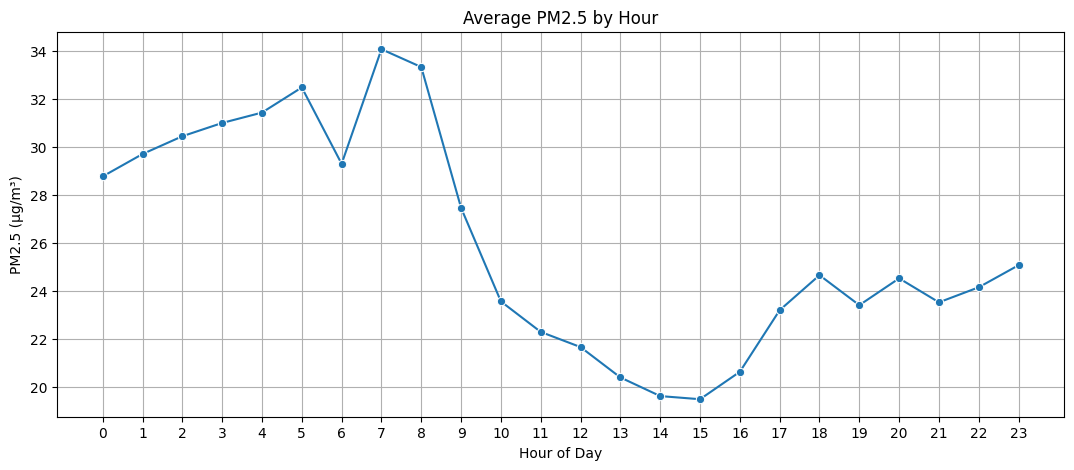

In [44]:
hourly_pm25 = (
    df_clean
    .groupby("hour")["pm25_ugm3"]
    .mean()
)

plt.figure(figsize=(13, 5))

sns.lineplot(
    x=hourly_pm25.index,
    y=hourly_pm25.values,
    marker="o"
)

plt.title("Average PM2.5 by Hour")
plt.xlabel("Hour of Day")
plt.ylabel("PM2.5 (µg/m³)")
plt.xticks(range(24))
plt.grid(True)

plt.show()

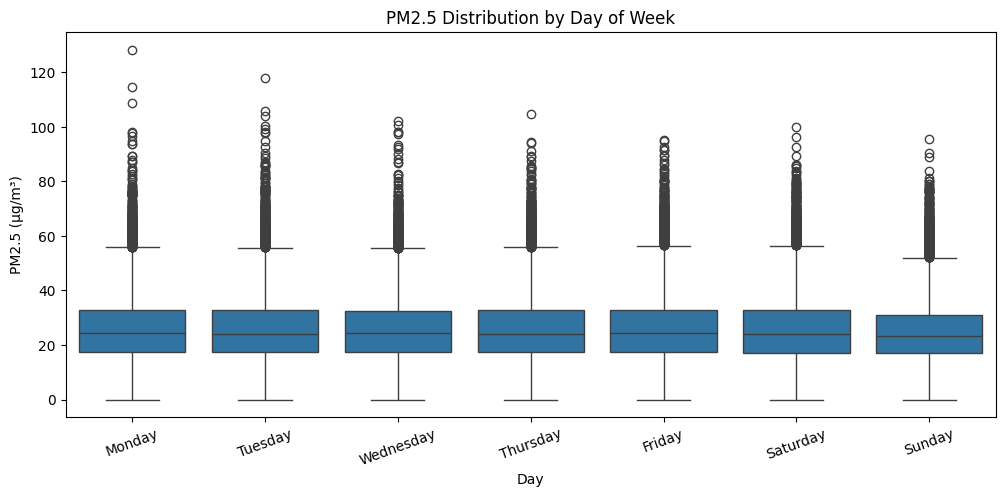

In [45]:
day_order = [
    "Monday",
    "Tuesday",
    "Wednesday",
    "Thursday",
    "Friday",
    "Saturday",
    "Sunday"
]

df_clean["day_name"] = df_clean["waktu"].dt.day_name()

plt.figure(figsize=(12, 5))

sns.boxplot(
    data=df_clean,
    x="day_name",
    y="pm25_ugm3",
    order=day_order
)

plt.title("PM2.5 Distribution by Day of Week")
plt.xlabel("Day")
plt.ylabel("PM2.5 (µg/m³)")
plt.xticks(rotation=20)

plt.show()

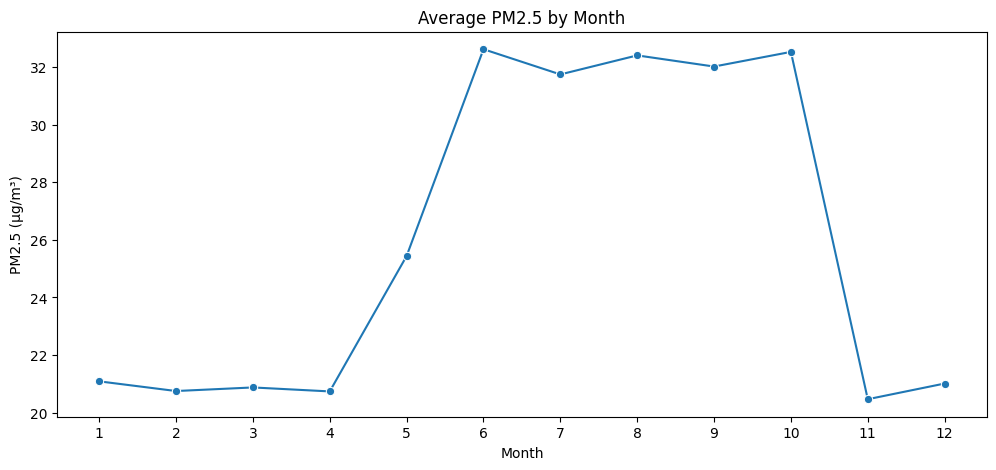

In [46]:
monthly_pm25 = (
    df_clean
    .groupby("month")["pm25_ugm3"]
    .mean()
)

plt.figure(figsize=(12, 5))

sns.lineplot(
    x=monthly_pm25.index,
    y=monthly_pm25.values,
    marker="o"
)

plt.title("Average PM2.5 by Month")
plt.xlabel("Month")
plt.ylabel("PM2.5 (µg/m³)")
plt.xticks(range(1, 13))
plt.show()

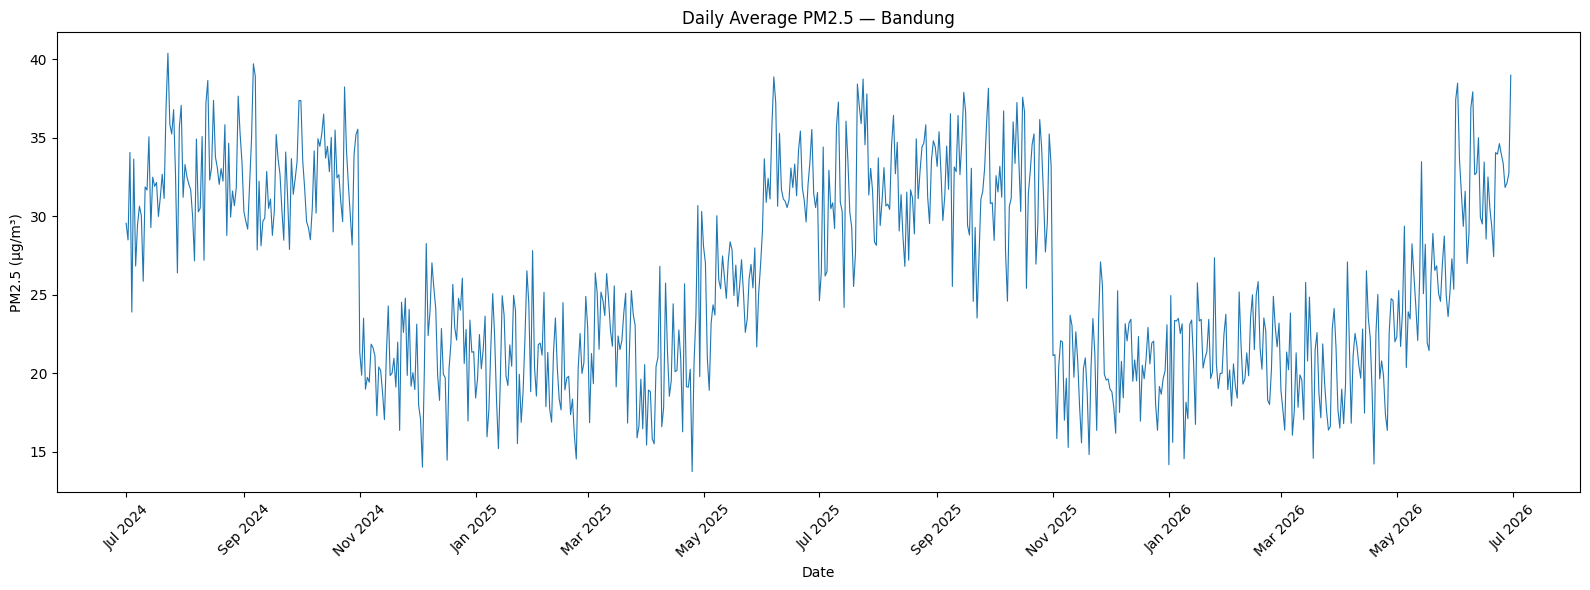

In [47]:
daily_pm25 = (
    df_clean
    .set_index("waktu")
    ["pm25_ugm3"]
    .resample("D")
    .mean()
)

plt.figure(figsize=(16, 6))

plt.plot(
    daily_pm25.index,
    daily_pm25.values,
    linewidth=0.8
)

plt.title("Daily Average PM2.5 — Bandung")
plt.xlabel("Date")
plt.ylabel("PM2.5 (µg/m³)")

plt.gca().xaxis.set_major_locator(
    mdates.MonthLocator(interval=2)
)

plt.gca().xaxis.set_major_formatter(
    mdates.DateFormatter("%b %Y")
)

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## 6. Spasial Analisis Perbandingan antarstasiun

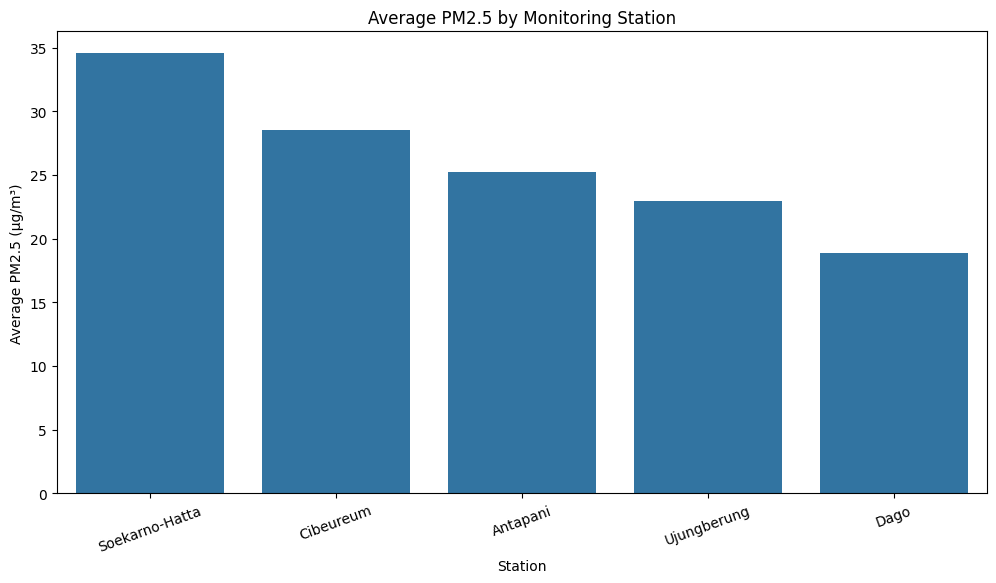

In [48]:
plt.figure(figsize=(12, 6))

station_mean = (
    df_clean
    .groupby("stasiun")["pm25_ugm3"]
    .mean()
    .sort_values(ascending=False)
)

sns.barplot(
    x=station_mean.index,
    y=station_mean.values
)

plt.title("Average PM2.5 by Monitoring Station")
plt.xlabel("Station")
plt.ylabel("Average PM2.5 (µg/m³)")
plt.xticks(rotation=20)

plt.show()

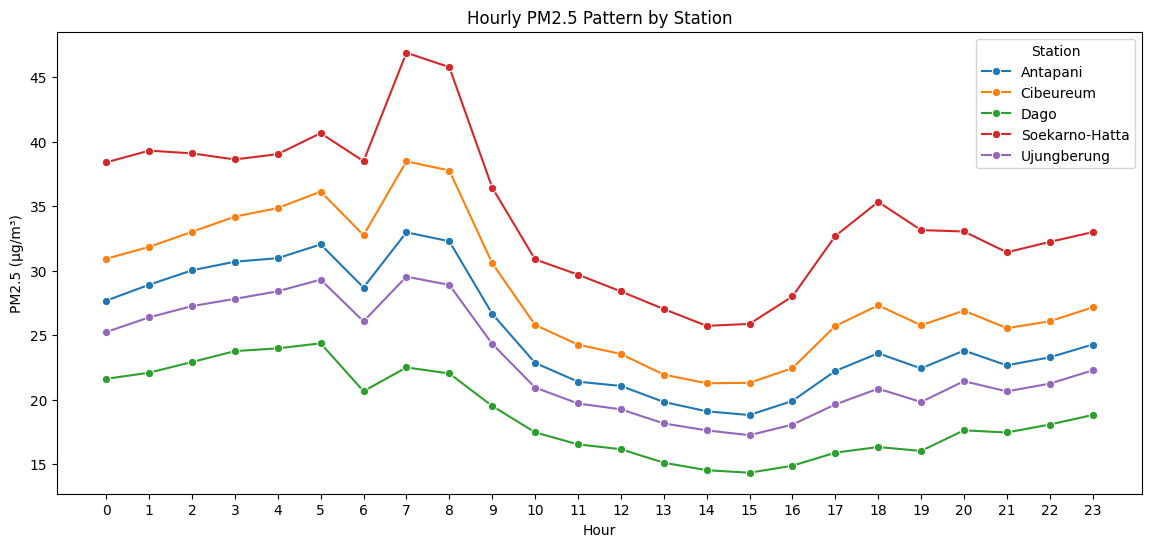

In [49]:
plt.figure(figsize=(14, 6))

sns.lineplot(
    data=df_clean,
    x="hour",
    y="pm25_ugm3",
    hue="stasiun",
    estimator="mean",
    errorbar=None,
    marker="o"
)

plt.title("Hourly PM2.5 Pattern by Station")
plt.xlabel("Hour")
plt.ylabel("PM2.5 (µg/m³)")
plt.xticks(range(24))
plt.legend(title="Station")
plt.show()

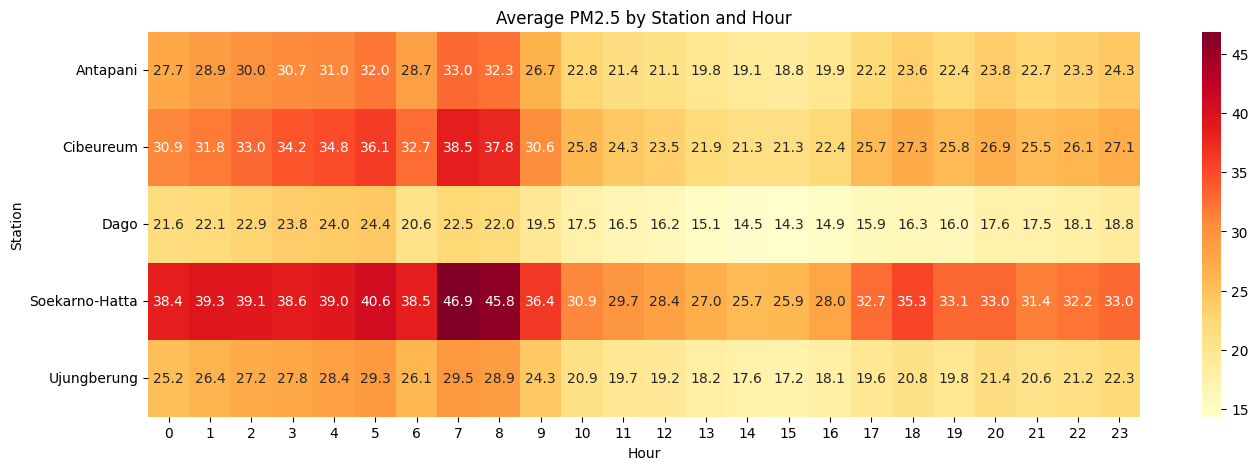

In [50]:
station_hour = df_clean.pivot_table(
    index="stasiun",
    columns="hour",
    values="pm25_ugm3",
    aggfunc="mean"
)

plt.figure(figsize=(16, 5))

sns.heatmap(
    station_hour,
    cmap="YlOrRd",
    annot=True,
    fmt=".1f"
)

plt.title("Average PM2.5 by Station and Hour")
plt.xlabel("Hour")
plt.ylabel("Station")

plt.show()

## 7. Multivariat Analisis

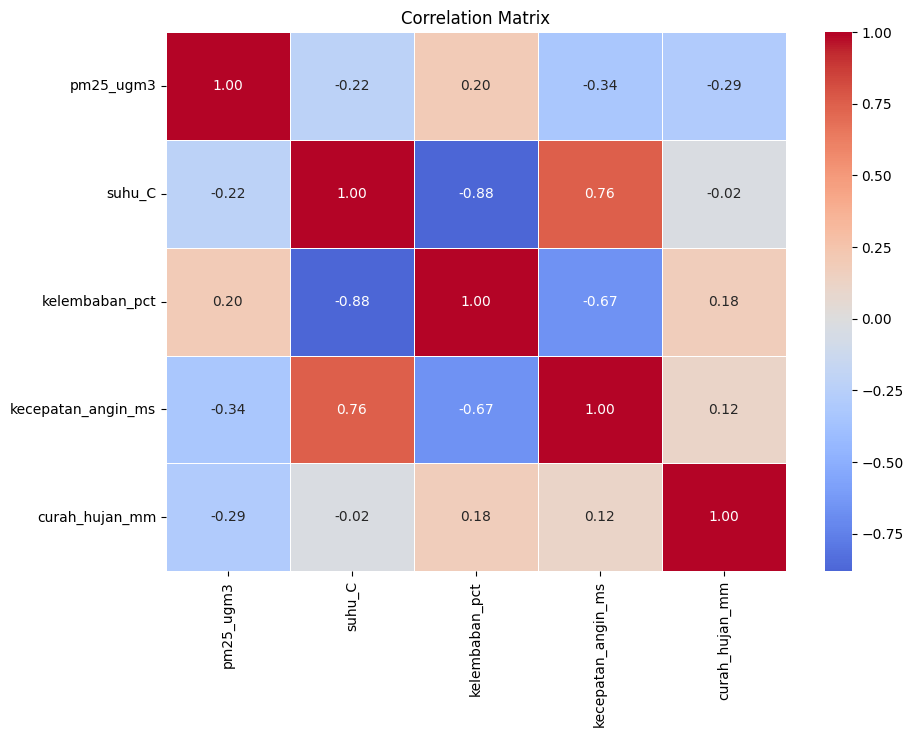

In [51]:
correlation_features = [
    "pm25_ugm3",
    "suhu_C",
    "kelembaban_pct",
    "kecepatan_angin_ms",
    "curah_hujan_mm"
]

correlation_matrix = df_clean[
    correlation_features
].corr(method="pearson")

plt.figure(figsize=(10, 7))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    center=0,
    fmt=".2f",
    linewidths=0.5
)

plt.title("Correlation Matrix")
plt.show()

In [52]:
angle_rad = np.deg2rad(df_clean["arah_angin_deg"])

df_clean["wind_sin"] = np.sin(angle_rad)
df_clean["wind_cos"] = np.cos(angle_rad)

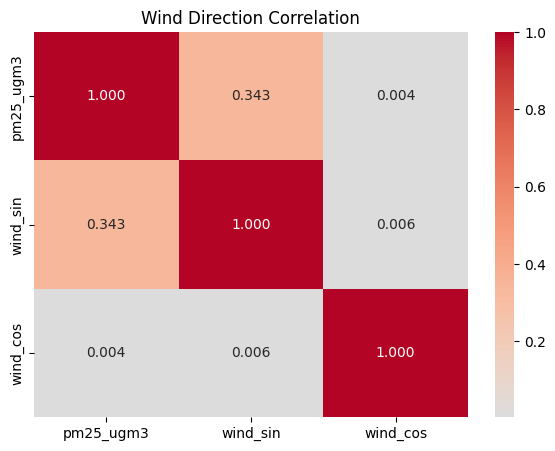

In [54]:
wind_corr = df_clean[
    [
        "pm25_ugm3",
        "wind_sin",
        "wind_cos"
    ]
].corr()

plt.figure(figsize=(7, 5))

sns.heatmap(
    wind_corr,
    annot=True,
    cmap="coolwarm",
    center=0,
    fmt=".3f"
)

plt.title("Wind Direction Correlation")
plt.show()

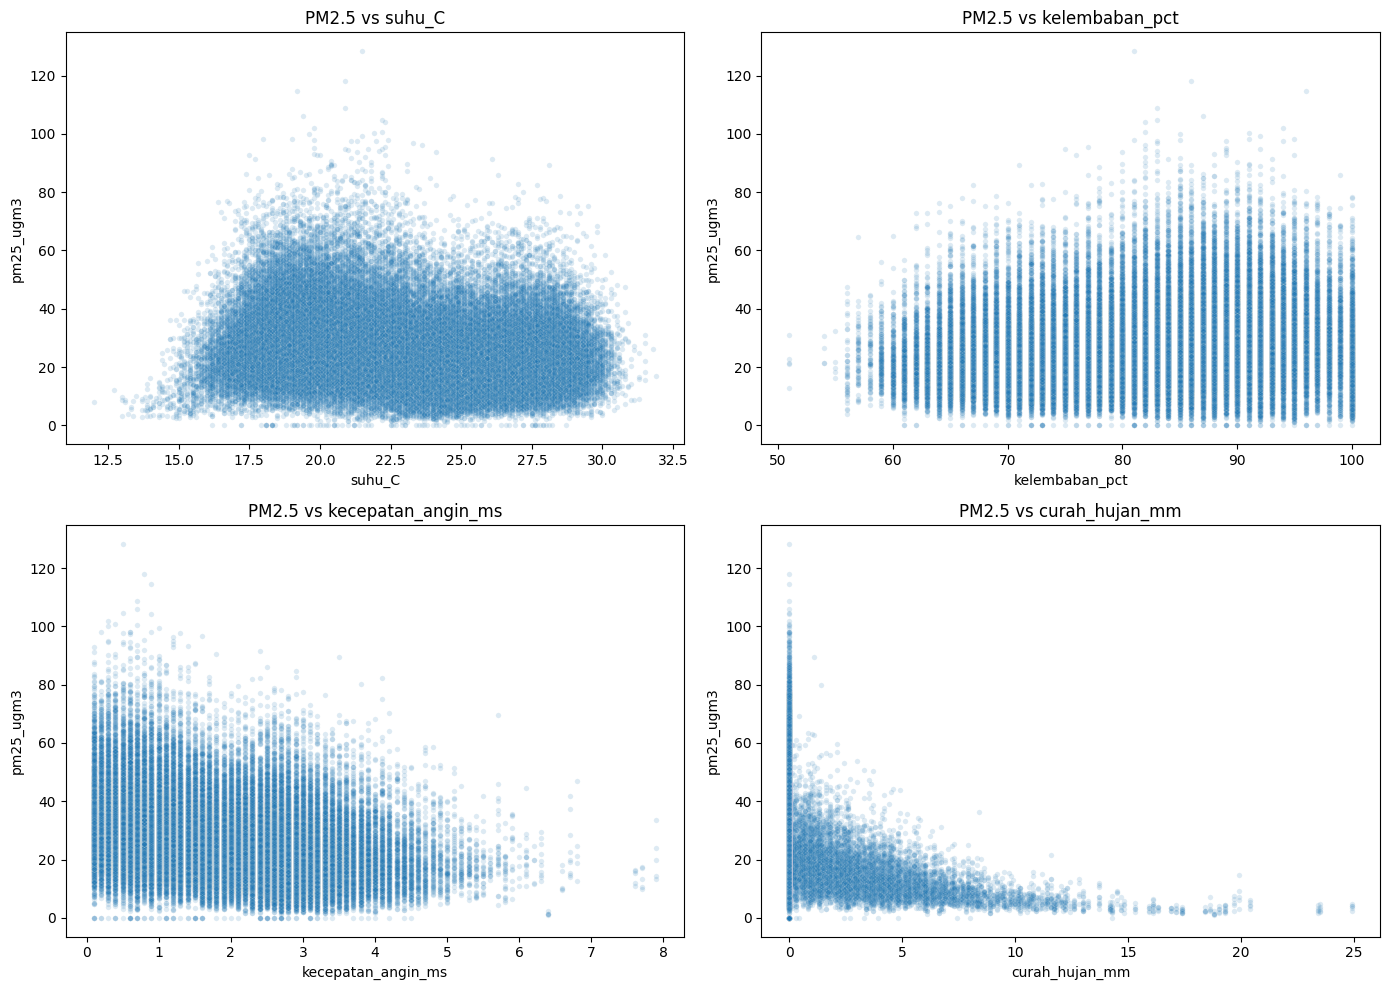

In [55]:
weather_features = [
    "suhu_C",
    "kelembaban_pct",
    "kecepatan_angin_ms",
    "curah_hujan_mm"
]

fig, axes = plt.subplots(
    2, 2,
    figsize=(14, 10)
)

axes = axes.flatten()

for i, feature in enumerate(weather_features):
    sns.scatterplot(
        data=df_clean,
        x=feature,
        y="pm25_ugm3",
        alpha=0.15,
        s=15,
        ax=axes[i]
    )

    axes[i].set_title(
        f"PM2.5 vs {feature}"
    )

plt.tight_layout()
plt.show()

## 8.Time-Series Analisis

AttributeError: Line2D.set() got an unexpected keyword argument 'figsize'

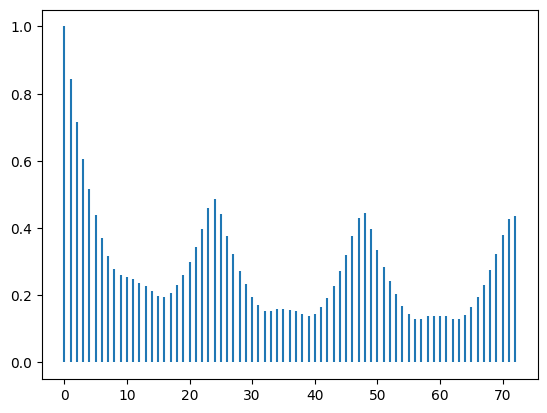

In [56]:
from statsmodels.graphics.tsaplots import plot_acf

station_data = (
    df_clean[
        df_clean["stasiun"] == "Soekarno-Hatta"
    ]
    .sort_values("waktu")
    .set_index("waktu")
)

# Resample to hourly frequency
pm25_series = station_data[
    "pm25_ugm3"
].resample("h").mean()

# ACF
plot_acf(
    pm25_series.dropna(),
    lags=72,
    missing="drop",
    figsize=(14, 5)
)

plt.title("PM2.5 Autocorrelation — Soekarno-Hatta")
plt.show()

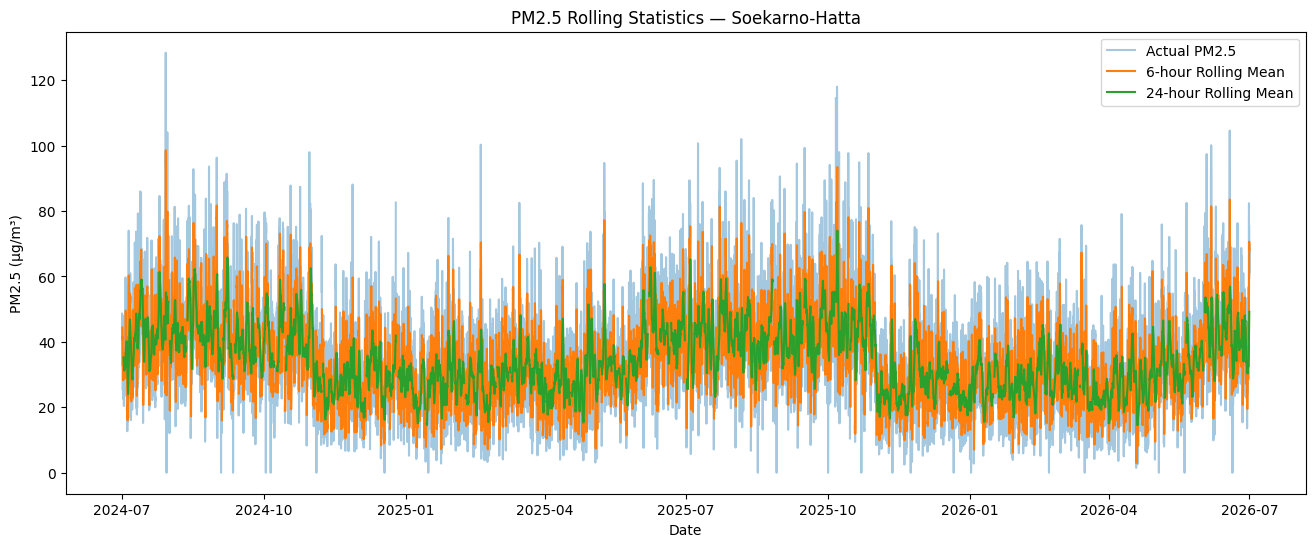

In [57]:
station_data = station_data.copy()

station_data["rolling_6h"] = (
    station_data["pm25_ugm3"]
    .rolling(window=6, min_periods=6)
    .mean()
)

station_data["rolling_24h"] = (
    station_data["pm25_ugm3"]
    .rolling(window=24, min_periods=24)
    .mean()
)

plt.figure(figsize=(16, 6))

plt.plot(
    station_data.index,
    station_data["pm25_ugm3"],
    alpha=0.4,
    label="Actual PM2.5"
)

plt.plot(
    station_data.index,
    station_data["rolling_6h"],
    label="6-hour Rolling Mean"
)

plt.plot(
    station_data.index,
    station_data["rolling_24h"],
    label="24-hour Rolling Mean"
)

plt.title("PM2.5 Rolling Statistics — Soekarno-Hatta")
plt.xlabel("Date")
plt.ylabel("PM2.5 (µg/m³)")
plt.legend()

plt.show()

## 9. Analisis Kelengkapan Data Time Series

In [58]:
station_coverage = (
    df_clean
    .groupby("stasiun")
    .agg(
        total_rows=("waktu", "count"),
        first_timestamp=("waktu", "min"),
        last_timestamp=("waktu", "max"),
        unique_timestamps=("waktu", "nunique")
    )
)

display(station_coverage)

,total_rows,first_timestamp,last_timestamp,unique_timestamps
stasiun,,,,
Antapani,17456,2024-07-01,2026-06-30 23:00:00,17456
Cibeureum,17443,2024-07-01,2026-06-30 23:00:00,17443
Dago,17455,2024-07-01,2026-06-30 23:00:00,17455
Soekarno-Hatta,17430,2024-07-01,2026-06-30 23:00:00,17430
Ujungberung,17454,2024-07-01,2026-06-30 23:00:00,17454


In [59]:
missing_hours = {}

for station in df_clean["stasiun"].dropna().unique():

    station_df = (
        df_clean[df_clean["stasiun"] == station]
        .sort_values("waktu")
    )

    expected = pd.date_range(
        start=station_df["waktu"].min(),
        end=station_df["waktu"].max(),
        freq="h"
    )

    actual = pd.DatetimeIndex(
        station_df["waktu"].dropna().unique()
    )

    missing = expected.difference(actual)

    missing_hours[station] = len(missing)

    print(
        f"{station}: {len(missing)} missing timestamps"
    )

Antapani: 64 missing timestamps
Cibeureum: 77 missing timestamps
Dago: 65 missing timestamps
Soekarno-Hatta: 90 missing timestamps
Ujungberung: 66 missing timestamps


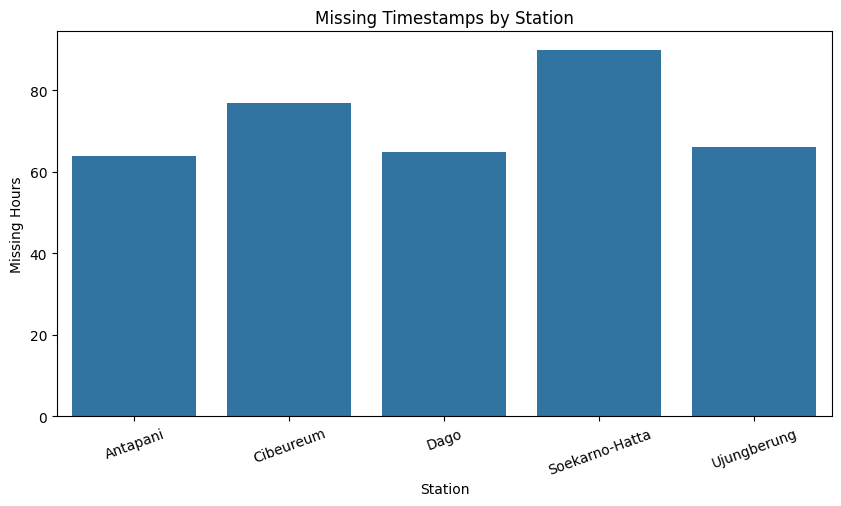

In [60]:
plt.figure(figsize=(10, 5))

sns.barplot(
    x=list(missing_hours.keys()),
    y=list(missing_hours.values())
)

plt.title("Missing Timestamps by Station")
plt.xlabel("Station")
plt.ylabel("Missing Hours")
plt.xticks(rotation=20)

plt.show()

In [61]:
future_target = df_clean[
    ["waktu", "stasiun", "pm25_ugm3"]
].copy()

future_target = future_target.rename(
    columns={
        "waktu": "target_time",
        "pm25_ugm3": "target_pm25"
    }
)

# Current observation time + 3 hours
df_model = df_clean.copy()

df_model["target_time"] = (
    df_model["waktu"] + pd.Timedelta(hours=3)
)

# Match future PM2.5 using exact timestamp and same station
df_model = df_model.merge(
    future_target,
    on=["target_time", "stasiun"],
    how="left",
    validate="many_to_one"
)

print("Model dataset shape:", df_model.shape)

display(
    df_model[
        [
            "waktu",
            "target_time",
            "stasiun",
            "pm25_ugm3",
            "target_pm25"
        ]
    ].head(10)
)

Model dataset shape: (87238, 19)


,waktu,target_time,stasiun,pm25_ugm3,target_pm25
0,2024-07-01 00:00:00,2024-07-01 03:00:00,Antapani,34.9,34.2
1,2024-07-01 01:00:00,2024-07-01 04:00:00,Antapani,33.1,37.6
2,2024-07-01 02:00:00,2024-07-01 05:00:00,Antapani,38.2,25.7
3,2024-07-01 03:00:00,2024-07-01 06:00:00,Antapani,34.2,30.7
4,2024-07-01 04:00:00,2024-07-01 07:00:00,Antapani,37.6,30.3
5,2024-07-01 05:00:00,2024-07-01 08:00:00,Antapani,25.7,27.2
6,2024-07-01 06:00:00,2024-07-01 09:00:00,Antapani,30.7,25.1
7,2024-07-01 07:00:00,2024-07-01 10:00:00,Antapani,30.3,22.6
8,2024-07-01 08:00:00,2024-07-01 11:00:00,Antapani,27.2,23.8
9,2024-07-01 09:00:00,2024-07-01 12:00:00,Antapani,25.1,21.1


In [62]:
target_missing = df_model["target_pm25"].isna().sum()

target_missing_percentage = (
    df_model["target_pm25"].isna().mean() * 100
)

print("Missing targets:", target_missing)
print(
    "Missing target percentage:",
    round(target_missing_percentage, 2),
    "%"
)

Missing targets: 681
Missing target percentage: 0.78 %


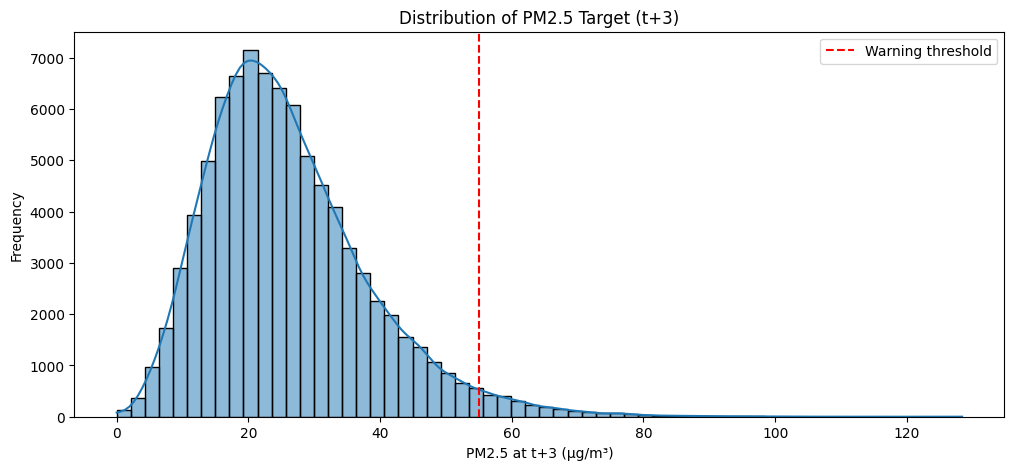

In [63]:
plt.figure(figsize=(12, 5))

sns.histplot(
    data=df_model,
    x="target_pm25",
    bins=60,
    kde=True
)

plt.axvline(
    55,
    color="red",
    linestyle="--",
    label="Warning threshold"
)

plt.title("Distribution of PM2.5 Target (t+3)")
plt.xlabel("PM2.5 at t+3 (µg/m³)")
plt.ylabel("Frequency")
plt.legend()

plt.show()

In [64]:
target_station_stats = (
    df_model
    .groupby("stasiun")["target_pm25"]
    .agg([
        "count",
        "mean",
        "median",
        "std",
        "min",
        "max"
    ])
    .round(2)
)

display(target_station_stats)

,count,mean,median,std,min,max
stasiun,,,,,,
Antapani,17359,25.25,24.0,10.71,0.0,86.2
Cibeureum,17187,28.54,27.1,12.05,0.0,95.1
Dago,17356,18.85,18.0,7.93,0.0,59.8
Soekarno-Hatta,17305,34.54,32.7,14.79,0.0,128.4
Ujungberung,17350,22.91,22.0,9.29,0.0,78.0


In [65]:
# Define split boundaries
train_end = pd.Timestamp("2026-03-01")
validation_end = pd.Timestamp("2026-05-01")
test_end = pd.Timestamp("2026-07-01")

# Keep only rows with valid target
df_model_valid = df_model.dropna(
    subset=["target_pm25"]
).copy()

# Temporal split based on target timestamp
train_df = df_model_valid[
    df_model_valid["target_time"] < train_end
].copy()

val_df = df_model_valid[
    (df_model_valid["target_time"] >= train_end) &
    (df_model_valid["target_time"] < validation_end)
].copy()

test_df = df_model_valid[
    (df_model_valid["target_time"] >= validation_end) &
    (df_model_valid["target_time"] < test_end)
].copy()

print("Train:", train_df.shape)
print("Validation:", val_df.shape)
print("Test:", test_df.shape)

Train: (72043, 19)
Validation: (7262, 19)
Test: (7252, 19)


In [66]:
split_summary = pd.DataFrame({
    "Dataset": ["Train", "Validation", "Test"],
    "Rows": [
        len(train_df),
        len(val_df),
        len(test_df)
    ],
    "Start": [
        train_df["target_time"].min(),
        val_df["target_time"].min(),
        test_df["target_time"].min()
    ],
    "End": [
        train_df["target_time"].max(),
        val_df["target_time"].max(),
        test_df["target_time"].max()
    ]
})

display(split_summary)

,Dataset,Rows,Start,End
0,Train,72043,2024-07-01 03:00:00,2026-02-28 23:00:00
1,Validation,7262,2026-03-01 00:00:00,2026-04-30 23:00:00
2,Test,7252,2026-05-01 00:00:00,2026-06-30 23:00:00


In [67]:
from sklearn.metrics import mean_absolute_error

def evaluate_persistence(data, dataset_name):

    valid = data.dropna(
        subset=["pm25_ugm3", "target_pm25"]
    )

    y_true = valid["target_pm25"]
    y_pred = valid["pm25_ugm3"]

    mae = mean_absolute_error(
        y_true,
        y_pred
    )

    # Warning detection
    actual_warning = y_true > 55
    predicted_warning = y_pred > 55

    true_positive = (
        actual_warning & predicted_warning
    ).sum()

    false_negative = (
        actual_warning & ~predicted_warning
    ).sum()

    recall = (
        true_positive / (true_positive + false_negative)
        if (true_positive + false_negative) > 0
        else np.nan
    )

    return {
        "Dataset": dataset_name,
        "Samples": len(valid),
        "MAE": mae,
        "Warning Recall": recall
    }


baseline_results = pd.DataFrame([
    evaluate_persistence(train_df, "Train"),
    evaluate_persistence(val_df, "Validation"),
    evaluate_persistence(test_df, "Test")
])

display(baseline_results.round(4))

,Dataset,Samples,MAE,Warning Recall
0,Train,71901,6.8618,0.3557
1,Validation,7246,6.2476,0.1860
2,Test,7236,6.5583,0.3013
